# Chapter 5: Bars, Pies and Tables

Companion notebook for *Master Data Visualization: A Hands-On Beginner's Guide with Python, Matplotlib, Seaborn & Plotly*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files this chapter uses are in the same folder as this notebook.

## 5.1 Bar Charts

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use('book.mplstyle')

In [2]:
products = pd.read_csv('product_sales.csv')
products

,product,units,revenue
0,Webcam,212,54900
1,Keyboard,388,50040
2,Monitor,96,33500
3,Headphones,251,37650
4,USB Cable,1240,24680
5,Mouse,530,15370
6,Laptop Stand,174,8530


### `ax.bar()`

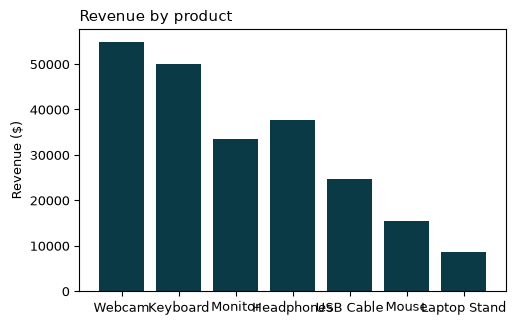

In [3]:
fig, ax = plt.subplots()
ax.bar(products['product'], products['revenue'])
ax.set_title('Revenue by product')
ax.set_ylabel('Revenue ($)')
plt.show()

### `df.sort_values()` before plotting

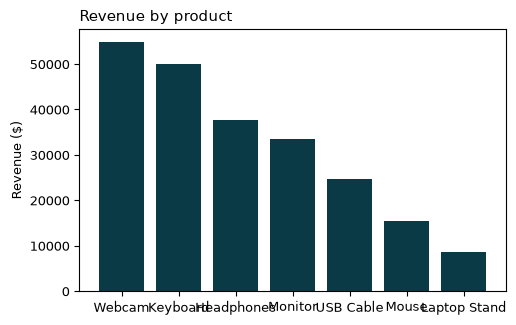

In [4]:
by_revenue = products.sort_values('revenue', ascending=False)

fig, ax = plt.subplots()
ax.bar(by_revenue['product'], by_revenue['revenue'])
ax.set_title('Revenue by product')
ax.set_ylabel('Revenue ($)')
plt.show()

### `ax.barh()`

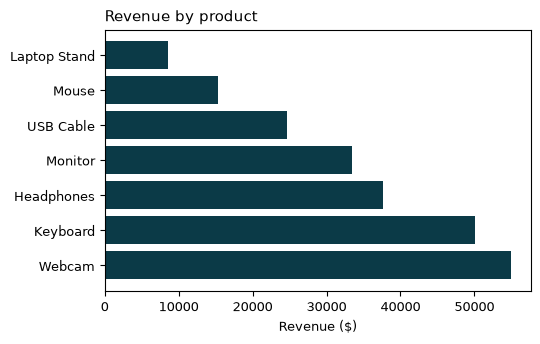

In [5]:
fig, ax = plt.subplots()
ax.barh(by_revenue['product'], by_revenue['revenue'])
ax.set_title('Revenue by product')
ax.set_xlabel('Revenue ($)')
plt.show()

### `ax.invert_yaxis()`

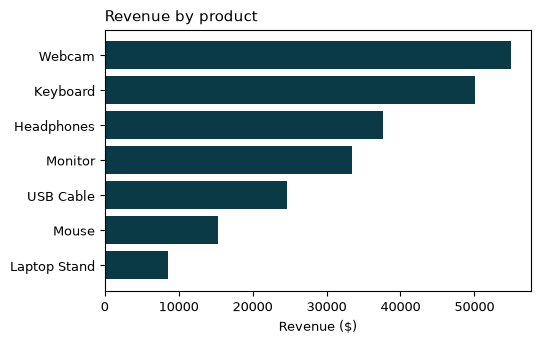

In [6]:
fig, ax = plt.subplots()
ax.barh(by_revenue['product'], by_revenue['revenue'])
ax.invert_yaxis()
ax.set_title('Revenue by product')
ax.set_xlabel('Revenue ($)')
plt.show()

### Highlighting one bar

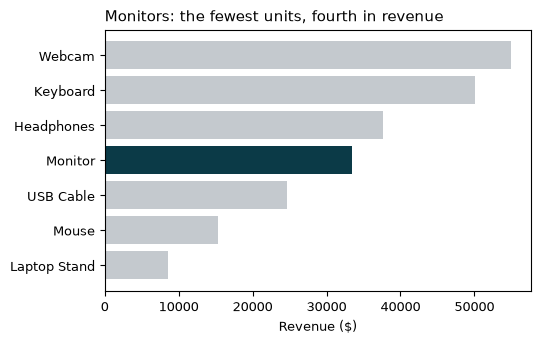

In [7]:
colors = np.where(by_revenue['product'] == 'Monitor',
                  '#0b3a47', '#c4c9ce')

fig, ax = plt.subplots()
ax.barh(by_revenue['product'], by_revenue['revenue'], color=colors)
ax.invert_yaxis()
ax.set_title('Monitors: the fewest units, fourth in revenue')
ax.set_xlabel('Revenue ($)')
plt.show()

## 5.2 Labels on Bars

### `ax.bar_label()`

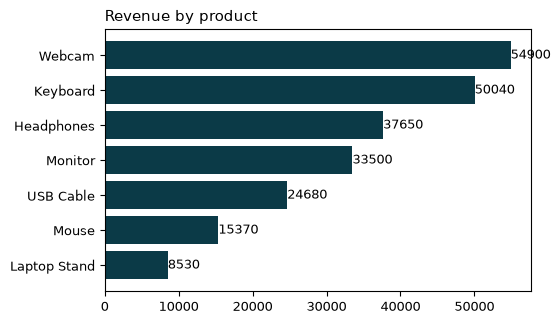

In [8]:
fig, ax = plt.subplots()
bars = ax.barh(by_revenue['product'], by_revenue['revenue'])
ax.bar_label(bars)
ax.invert_yaxis()
ax.set_title('Revenue by product')
plt.show()

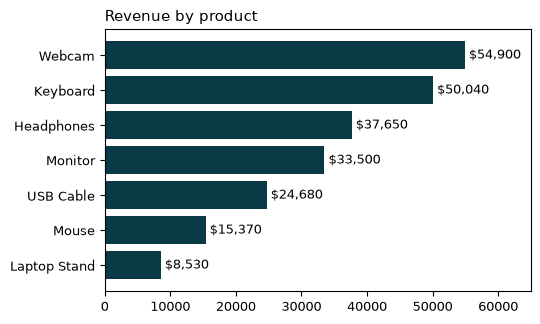

In [9]:
fig, ax = plt.subplots()
bars = ax.barh(by_revenue['product'], by_revenue['revenue'])
ax.bar_label(bars, fmt='${:,.0f}', padding=3)
ax.invert_yaxis()
ax.set_xlim(0, 65000)
ax.set_title('Revenue by product')
plt.show()

## 5.3 Grouped and Stacked Bars

In [10]:
regions = pd.read_csv('region_quarter.csv', index_col='region')
regions

,Q1,Q2,Q3,Q4
region,,,,
Northeast,41,44,47,63
South,36,39,40,52
Midwest,28,27,30,38
West,52,57,61,79


### Grouped bars with `ax.bar()`

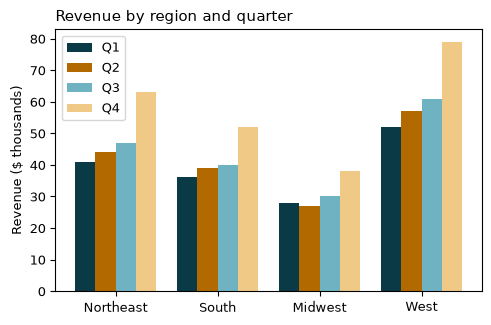

In [11]:
x = np.arange(len(regions))
width = 0.2

fig, ax = plt.subplots()
ax.bar(x - 0.3, regions['Q1'], width, label='Q1')
ax.bar(x - 0.1, regions['Q2'], width, label='Q2')
ax.bar(x + 0.1, regions['Q3'], width, label='Q3')
ax.bar(x + 0.3, regions['Q4'], width, label='Q4')
ax.set_xticks(x, regions.index)
ax.set_title('Revenue by region and quarter')
ax.set_ylabel('Revenue ($ thousands)')
ax.legend()
plt.show()

### Stacked bars with `bottom=`

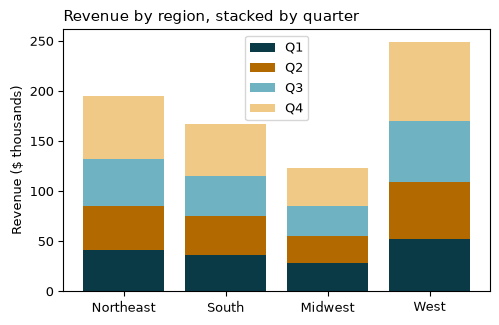

In [12]:
fig, ax = plt.subplots()
bottom = np.zeros(len(regions))
for quarter in ['Q1', 'Q2', 'Q3', 'Q4']:
    ax.bar(regions.index, regions[quarter], bottom=bottom,
           label=quarter)
    bottom = bottom + regions[quarter]
ax.set_title('Revenue by region, stacked by quarter')
ax.set_ylabel('Revenue ($ thousands)')
ax.legend()
plt.show()

### `df.plot(kind='bar')`

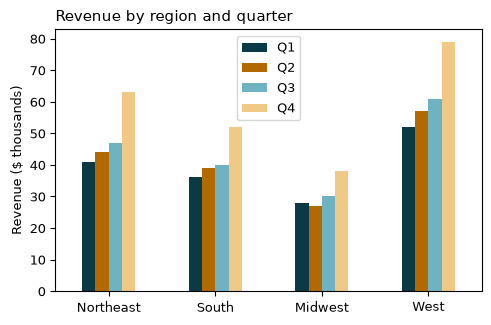

In [13]:
ax = regions.plot(kind='bar', rot=0)
ax.set_title('Revenue by region and quarter')
ax.set_xlabel('')
ax.set_ylabel('Revenue ($ thousands)')
plt.show()

### `df.plot.barh(stacked=True)`

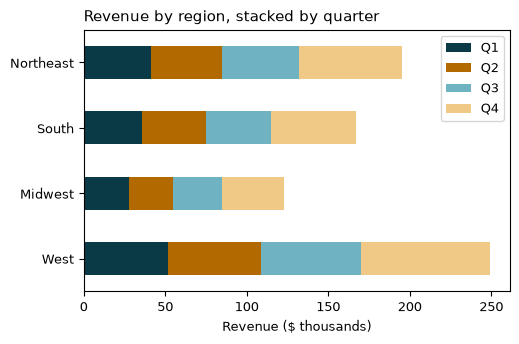

In [14]:
ax = regions.plot.barh(stacked=True)
ax.invert_yaxis()
ax.set_title('Revenue by region, stacked by quarter')
ax.set_xlabel('Revenue ($ thousands)')
ax.set_ylabel('')
plt.show()

## 5.4 Area Charts

In [15]:
channels = pd.read_csv('channel_monthly.csv', index_col='month')
channels.head(3)

,Online,In store,Phone
month,,,
Jan,15100,8900,2600
Feb,14600,8100,2500
Mar,17800,9300,2700


### `df.plot.area()`

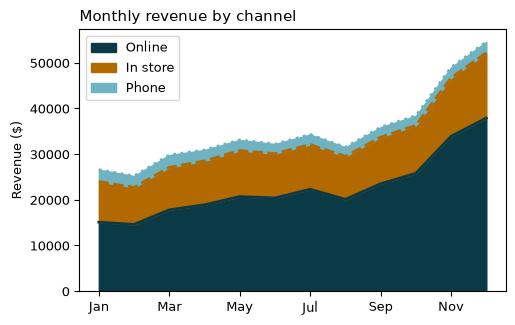

In [16]:
ax = channels.plot.area()
ax.set_title('Monthly revenue by channel')
ax.set_xlabel('')
ax.set_ylabel('Revenue ($)')
plt.show()

## 5.5 Pie and Donut Charts

In [17]:
channel_totals = pd.read_csv('channel_sales.csv')
channel_totals

,channel,revenue
0,Online,271000
1,In store,122700
2,Phone,27800


### `ax.pie()`

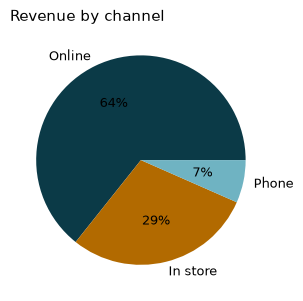

In [18]:
fig, ax = plt.subplots()
ax.pie(channel_totals['revenue'], labels=channel_totals['channel'],
       autopct='%1.0f%%')
ax.set_title('Revenue by channel')
plt.show()

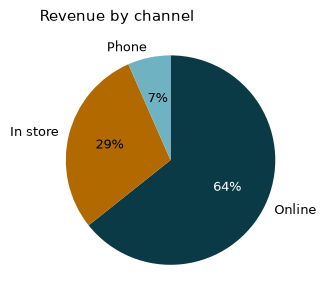

In [19]:
fig, ax = plt.subplots()
wedges, labels, pcts = ax.pie(
    channel_totals['revenue'], labels=channel_totals['channel'],
    autopct='%1.0f%%', startangle=90, counterclock=False)
pcts[0].set_color('white')
ax.set_title('Revenue by channel')
plt.show()

### Donut charts

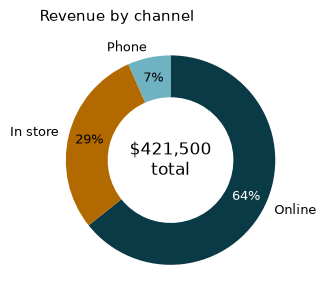

In [20]:
total = channel_totals['revenue'].sum()

fig, ax = plt.subplots()
wedges, labels, pcts = ax.pie(
    channel_totals['revenue'], labels=channel_totals['channel'],
    autopct='%1.0f%%', pctdistance=0.8, startangle=90,
    counterclock=False, wedgeprops={'width': 0.4})
pcts[0].set_color('white')
ax.text(0, 0, f'${total:,}\ntotal', ha='center', va='center',
        fontsize=12)
ax.set_title('Revenue by channel')
plt.show()

## 5.6 Tables with Color

### `df.style.background_gradient()`

In [21]:
regions.style.background_gradient(cmap='GnBu')

,Q1,Q2,Q3,Q4
region,,,,
Northeast,41,44,47,63
South,36,39,40,52
Midwest,28,27,30,38
West,52,57,61,79


In [22]:
regions.style.background_gradient(cmap='GnBu', axis=None)

,Q1,Q2,Q3,Q4
region,,,,
Northeast,41,44,47,63
South,36,39,40,52
Midwest,28,27,30,38
West,52,57,61,79


### `df.style.bar()`

In [23]:
(by_revenue.style
    .bar(subset=['revenue'], color='#6fb3c2')
    .format({'revenue': '${:,}'})
    .hide(axis='index'))

product,units,revenue
Webcam,212,"$54,900"
Keyboard,388,"$50,040"
Headphones,251,"$37,650"
Monitor,96,"$33,500"
USB Cable,1240,"$24,680"
Mouse,530,"$15,370"
Laptop Stand,174,"$8,530"
